
# Solution finale

Modèle unique entraîné sur les 34 000 clients, avec la colonne `STATUT`,
utilisé ensuite selon le profil du client.

| Liste | Population | Question | Action |
|---|---|---|---|
| Relances préventives | clients actifs | va-t-il partir ? | proposer une offre |
| Réactivations | clients suspendus | va-t-il revenir ? | proposer une recharge |

Le choix d'un modèle unique vient de la comparaison du notebook 04 : à
performance égale sur les clients actifs, un seul entraînement est plus simple.



## 1. Chargement


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FICHIER = ROOT / 'data' / 'final' / 'modele_operationnel.csv'

donnees = pd.read_csv(FICHIER, keep_default_na=False, na_values=[''], low_memory=False)

print('données :', donnees.shape)


données : (34000, 10)


In [2]:

X = donnees.drop(columns=['churn'])
y = donnees['churn']

print('variables :', list(X.columns))
print(f'label : churn, {y.mean()*100:.2f} % de clients qui partent')


variables : ['ANC_M', 'VOLUME_SESSION', 'MNT_RECH', 'MNT_FORFAIT', 'APPEL_TOTAL', 'SMS_TOTAL', 'HANDSET', 'OFFRE', 'STATUT']
label : churn, 28.12 % de clients qui partent


In [3]:

print('répartition de STATUT :')
print(donnees['STATUT'].value_counts().sort_index().to_string())
print()
print('0 = actif, 1 = suspendu')


répartition de STATUT :
STATUT
0    25466
1     8534

0 = actif, 1 = suspendu



## 2. Entraînement

Découpage 80 / 20 stratifié. 250 arbres de décision, learning_rate 0,06 :
chaque arbre ne pèse que 6 % du résultat, ce qui limite le surapprentissage.


In [4]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

print(f'entraînement : {len(X_train):,} clients')
print(f'test         : {len(X_test):,} clients')
print(f'churn entraînement : {y_train.mean()*100:.2f} %')
print(f'churn test         : {y_test.mean()*100:.2f} %')


entraînement : 27,200 clients
test         : 6,800 clients
churn entraînement : 28.12 %
churn test         : 28.12 %


In [5]:

modele = HistGradientBoostingClassifier(
    max_iter=250,
    learning_rate=0.06,
    random_state=42
)

modele.fit(X_train, y_train)
print('modèle entraîné')


modèle entraîné


In [6]:

proba = modele.predict_proba(X_test)[:, 1]

print('5 premières prédictions :')
for i in range(5):
    reel = 'part' if y_test.iloc[i] == 1 else 'reste'
    print(f'  {proba[i]*100:>5.1f} %  (réel : {reel})')


5 premières prédictions :
    4.6 %  (réel : reste)
   79.7 %  (réel : part)
    6.2 %  (réel : reste)
    2.7 %  (réel : reste)
   28.2 %  (réel : reste)



## 3. Évaluation

Le score global et le score par population ne disent pas la même chose.


In [7]:

auc_global = roc_auc_score(y_test, proba)
print(f'AUC globale : {auc_global:.4f}')


AUC globale : 0.9197


In [8]:

statut_test = X_test['STATUT'].to_numpy()
masque_actifs = (statut_test == 0)
masque_suspendus = (statut_test == 1)

y_test_array = y_test.to_numpy()

auc_actifs = roc_auc_score(y_test_array[masque_actifs], proba[masque_actifs])
auc_suspendus = roc_auc_score(y_test_array[masque_suspendus], proba[masque_suspendus])

print('AUC par population')
print(f'  actifs    : {masque_actifs.sum():>5,}  ->  {auc_actifs:.4f}')
print(f'  suspendus : {masque_suspendus.sum():>5,}  ->  {auc_suspendus:.4f}')
print(f'  global    : {len(y_test):>5,}  ->  {auc_global:.4f}')


AUC par population
  actifs    : 5,050  ->  0.8010
  suspendus : 1,750  ->  0.7096
  global    : 6,800  ->  0.9197


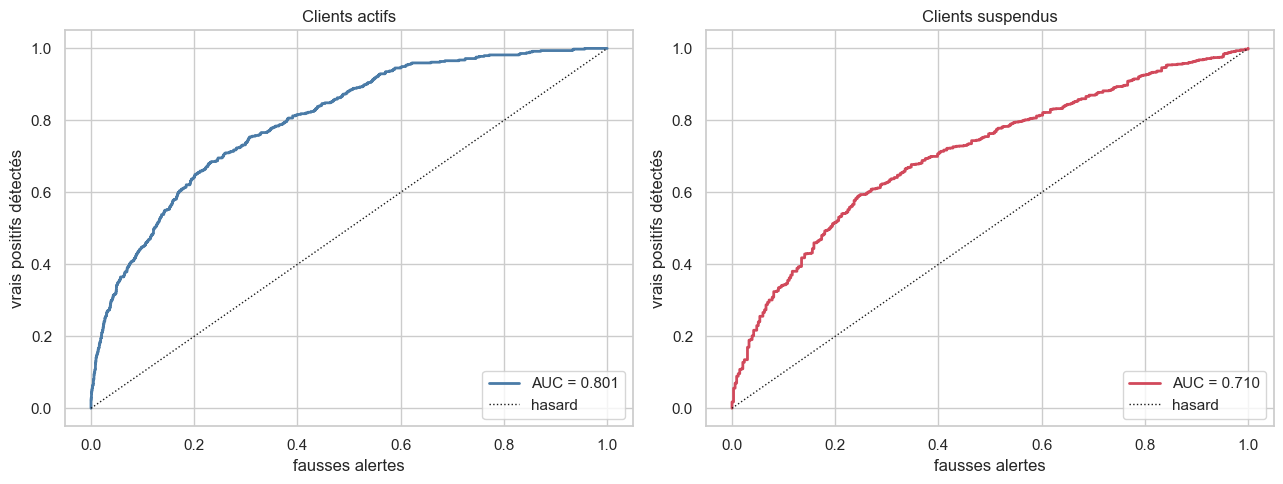

In [9]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, titre, masque, auc, couleur in [
        (axes[0], 'Clients actifs', masque_actifs, auc_actifs, '#4a7ba7'),
        (axes[1], 'Clients suspendus', masque_suspendus, auc_suspendus, '#d1495b')]:
    fpr, tpr, _ = roc_curve(y_test_array[masque], proba[masque])
    ax.plot(fpr, tpr, color=couleur, linewidth=2, label=f'AUC = {auc:.3f}')
    ax.plot([0, 1], [0, 1], 'k:', linewidth=1, label='hasard')
    ax.set_xlabel('fausses alertes')
    ax.set_ylabel('vrais positifs détectés')
    ax.set_title(titre)
    ax.legend(loc='lower right')

plt.tight_layout()
plt.show()



### Lecture

| Mesure | Valeur |
|---|---|
| AUC globale | 0,92 |
| AUC actifs | 0,80 |
| AUC suspendus | 0,71 |

L'AUC globale dépasse chacune des deux populations. Le modèle n'a pas besoin
de bien classer à l'intérieur d'un groupe : séparer les actifs (9,8 % de
churn) des suspendus (82,9 %) suffit. Pour décider, c'est le score de la
population concernée qui compte.



## 4. Stabilité

Un découpage unique peut tomber sur un tirage favorable. On répète
l'entraînement sur 5 découpages.


In [10]:

scores_actifs = []
scores_suspendus = []

for graine in range(5):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.20, random_state=graine, stratify=y)

    m = HistGradientBoostingClassifier(
        max_iter=250, learning_rate=0.06, random_state=0)
    m.fit(X_tr, y_tr)

    p = m.predict_proba(X_te)[:, 1]

    statut_te = X_te['STATUT'].to_numpy()
    actif = (statut_te == 0)
    suspendu = (statut_te == 1)

    y_te_array = y_te.to_numpy()
    scores_actifs.append(roc_auc_score(y_te_array[actif], p[actif]))
    scores_suspendus.append(roc_auc_score(y_te_array[suspendu], p[suspendu]))

print('5 découpages :')
print(f'  actifs    : {np.mean(scores_actifs):.4f}  +/- {np.std(scores_actifs):.4f}')
print(f'  suspendus : {np.mean(scores_suspendus):.4f}  +/- {np.std(scores_suspendus):.4f}')


5 découpages :
  actifs    : 0.8008  +/- 0.0078
  suspendus : 0.7080  +/- 0.0126



## 5. Les deux listes

| Population | Objectif | Tri |
|---|---|---|
| Actifs | les plus susceptibles de partir | churn décroissant |
| Suspendus | les plus susceptibles de revenir | churn croissant |

Le modèle prédit le départ. Pour les suspendus, un score élevé signifie donc
une faible chance de revenir : le tri est inversé.


In [11]:

resultats = X_test.copy()
resultats['probabilite_churn'] = proba
resultats['churn_reel'] = y_test.to_numpy()
resultats['population'] = np.where(masque_actifs, 'ACTIF', 'SUSPENDU')

liste_actifs = (
    resultats[resultats['population'] == 'ACTIF']
    .sort_values('probabilite_churn', ascending=False)
)

print('LISTE 1 — RELANCES (clients actifs)')
print(f'{"n":>3} {"risque":>8} {"ANC_M":>7} {"MNT_RECH":>9} {"réel":>7}')
for i, (_, l) in enumerate(liste_actifs.head(10).iterrows(), 1):
    reel = 'PART' if l['churn_reel'] == 1 else 'reste'
    print(f'{i:>3} {l["probabilite_churn"]*100:>7.1f}% {l["ANC_M"]:>7.0f} '
          f'{l["MNT_RECH"]:>9.1f} {reel:>7}')


LISTE 1 — RELANCES (clients actifs)
  n   risque   ANC_M  MNT_RECH    réel
  1    90.0%      24       1.0    PART
  2    89.8%      25       0.0    PART
  3    88.8%      24       0.0    PART
  4    87.7%      24       0.0    PART
  5    87.2%      37       5.0    PART
  6    86.6%      24       2.0    PART
  7    80.0%       5      30.0    PART
  8    79.9%       5      30.0    PART
  9    79.1%       5      35.0    PART
 10    79.0%      24       6.1    PART


In [12]:

liste_suspendus = (
    resultats[resultats['population'] == 'SUSPENDU']
    .sort_values('probabilite_churn', ascending=True)
)

print('LISTE 2 — RÉACTIVATIONS (clients suspendus)')
print(f'{"n":>3} {"chance":>8} {"ANC_M":>7} {"MNT_RECH":>9} {"réel":>9}')
for i, (_, l) in enumerate(liste_suspendus.head(10).iterrows(), 1):
    chance = (1 - l['probabilite_churn']) * 100
    reel = 'REVIENT' if l['churn_reel'] == 0 else 'part'
    print(f'{i:>3} {chance:>7.1f}% {l["ANC_M"]:>7.0f} '
          f'{l["MNT_RECH"]:>9.1f} {reel:>9}')


LISTE 2 — RÉACTIVATIONS (clients suspendus)
  n   chance   ANC_M  MNT_RECH      réel
  1    55.9%     256       3.2      part
  2    55.6%     232       2.9      part
  3    54.2%     276       3.4      part
  4    51.1%     253       4.8   REVIENT
  5    50.7%     263       3.9   REVIENT
  6    50.0%     194       4.8      part
  7    49.8%     160       2.9      part
  8    49.3%     197       4.9      part
  9    49.2%     196       4.5   REVIENT
 10    48.6%     263       2.9   REVIENT



## 6. Gain sur une liste d'appels


In [13]:

def mesurer_gain(liste, sens, tailles, nom):
    if sens == 'partir':
        base = liste['churn_reel'].mean() * 100
    else:
        base = (liste['churn_reel'] == 0).mean() * 100

    print(f'{nom} (hasard {base:.1f} %)')
    for n in tailles:
        if n > len(liste):
            continue
        if sens == 'partir':
            sel = liste.nlargest(n, 'probabilite_churn')
            positifs = int(sel['churn_reel'].sum())
        else:
            sel = liste.nsmallest(n, 'probabilite_churn')
            positifs = int((sel['churn_reel'] == 0).sum())

        taux = positifs / n * 100
        print(f'  top {n:>4,} : {positifs:>4,} positifs ({taux:>4.0f} %)  gain x{taux/base:.1f}')
    print()

mesurer_gain(liste_actifs, 'partir', [100, 300, 500], 'Relances')
mesurer_gain(liste_suspendus, 'revenir', [100, 300, 500], 'Réactivations')


Relances (hasard 9.8 %)
  top  100 :   61 positifs (  61 %)  gain x6.2
  top  300 :  136 positifs (  45 %)  gain x4.6
  top  500 :  188 positifs (  38 %)  gain x3.8

Réactivations (hasard 19.1 %)
  top  100 :   41 positifs (  41 %)  gain x2.1
  top  300 :  105 positifs (  35 %)  gain x1.8
  top  500 :  165 positifs (  33 %)  gain x1.7




## 7. Importance des variables

On mélange au hasard une colonne et on mesure la perte d'AUC.


In [14]:

importance = permutation_importance(
    modele, X_test, y_test,
    n_repeats=8, random_state=42, scoring='roc_auc'
)

tableau = pd.DataFrame({
    'variable': X.columns,
    'importance': importance.importances_mean,
    'ecart_type': importance.importances_std,
}).sort_values('importance', ascending=False)

print(tableau.round(4).to_string(index=False))


      variable  importance  ecart_type
        STATUT      0.2471      0.0035
      MNT_RECH      0.0285      0.0020
       HANDSET      0.0143      0.0010
         ANC_M      0.0086      0.0006
   APPEL_TOTAL      0.0080      0.0012
     SMS_TOTAL      0.0064      0.0010
VOLUME_SESSION      0.0011      0.0004
         OFFRE      0.0006      0.0002
   MNT_FORFAIT      0.0005      0.0004



### Lecture

`STATUT` domine : il sépare deux populations aux taux de churn très
différents. Viennent ensuite `MNT_RECH`, `HANDSET` et `ANC_M`.

Les variables à importance presque nulle (`VOLUME_SESSION`, `OFFRE`,
`MNT_FORFAIT`) pourraient être retirées sans perte notable.



## 8. Tableau de bord

Pour le reporting, un comptage sur `STATUT` suffit.


In [15]:

print('TABLEAU DE BORD')
print(f'Clients total : {len(donnees):,}')
print(f'Risque global : {donnees["churn"].mean()*100:.1f} %')
print()
print(f'{"":12s} {"clients":>9s} {"à risque":>10s} {"taux":>7s}')
for code_statut, nom in [(0, 'Actifs'), (1, 'Suspendus')]:
    groupe = donnees[donnees['STATUT'] == code_statut]
    a_risque = int(groupe['churn'].sum())
    taux = groupe['churn'].mean() * 100
    print(f'{nom:12s} {len(groupe):>9,} {a_risque:>10,} {taux:>6.1f} %')
print()
print('Actions : 300 relances + 300 réactivations')


TABLEAU DE BORD
Clients total : 34,000
Risque global : 28.1 %

               clients   à risque    taux
Actifs          25,466      2,487    9.8 %
Suspendus        8,534      7,073   82.9 %

Actions : 300 relances + 300 réactivations



## 9. Processus mensuel

```
1. Extraire les données du mois
2. Nettoyer (notebook 03)
3. Scorer avec le modèle
4. Séparer actifs et suspendus, trier chaque liste
5. Lancer les deux campagnes
6. Reporter avec le comptage STATUT
```


In [16]:

nouveaux = donnees.sample(1000, random_state=7).drop(columns=['churn'])

proba_nouveaux = modele.predict_proba(nouveaux)[:, 1]
est_actif = (nouveaux['STATUT'] == 0).to_numpy()

actifs_a_appeler = nouveaux[est_actif].copy()
actifs_a_appeler['risque'] = proba_nouveaux[est_actif]
actifs_a_appeler = actifs_a_appeler.sort_values('risque', ascending=False)

suspendus_a_contacter = nouveaux[~est_actif].copy()
suspendus_a_contacter['risque'] = proba_nouveaux[~est_actif]
suspendus_a_contacter = suspendus_a_contacter.sort_values('risque', ascending=True)

print(f'sur 1 000 clients :')
print(f'  {len(actifs_a_appeler):>4,} actifs    -> relances')
print(f'  {len(suspendus_a_contacter):>4,} suspendus -> réactivations')
print()
print('3 actifs prioritaires :')
print(actifs_a_appeler[['ANC_M', 'MNT_RECH', 'risque']].head(3).round(3).to_string(index=False))
print()
print('3 suspendus prioritaires :')
print(suspendus_a_contacter[['ANC_M', 'MNT_RECH', 'risque']].head(3).round(3).to_string(index=False))


sur 1 000 clients :
   736 actifs    -> relances
   264 suspendus -> réactivations

3 actifs prioritaires :
 ANC_M  MNT_RECH  risque
     5    30.000   0.793
    58    79.655   0.720
   200    62.727   0.675

3 suspendus prioritaires :
 ANC_M  MNT_RECH  risque
   160     2.909   0.502
   231     3.444   0.522
    89     3.727   0.524



## 10. Récapitulatif

| Population | AUC | Top 300 | Hasard |
|---|---|---|---|
| Actifs | 0,80 | environ 45 % de vrais partants | 9,8 % |
| Suspendus | 0,71 | environ 35 % de vrais revenants | 17,1 % |

Sur 300 clients actifs choisis par le modèle, environ 135 partent vraiment.
Un tirage au hasard en donnerait 29.

### Le point à retenir

Pour les suspendus, le tri est inversé : le modèle prédit le départ.

```python
actifs.sort_values('risque', ascending=False)
suspendus.sort_values('risque', ascending=True)
```

### Limites

1. Pas de validation temporelle : une seule observation par client.
2. Le modèle des suspendus est plus faible (0,71), le tri reste grossier.
3. `STATUT` pèse lourd, ce qui est attendu puisqu'il sépare deux populations
   très différentes.


In [17]:

# Sauvegarde du modèle et téléchargement du fichier .joblib.
# Utilise la variable `modele` définie à l'étape 2.

import joblib
import sklearn
import base64
from IPython.display import Javascript, display

if 'modele' not in globals():
    raise RuntimeError('Modèle absent. Exécuter le notebook depuis le début.')

dossier_projet = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
dossier_modeles = dossier_projet / 'models'
dossier_modeles.mkdir(exist_ok=True)

# le nom indique la version de scikit-learn : un .joblib n'est pas
# portable entre versions majeures
version = sklearn.__version__.split('.')
nom_fichier = f'modele_churn_sklearn{version[0]}{version[1]}.joblib'

fichier = dossier_modeles / nom_fichier
joblib.dump(modele, fichier)

contenu = base64.b64encode(fichier.read_bytes()).decode()
display(Javascript(f"""
    var lien = document.createElement("a");
    lien.href = "data:application/octet-stream;base64,{contenu}";
    lien.download = "{nom_fichier}";
    document.body.appendChild(lien);
    lien.click();
    lien.remove();
"""))

taille_ko = fichier.stat().st_size / 1024
print(f'{nom_fichier} ({taille_ko:.0f} Ko)')
print()
print('Backend :')
print('  import joblib')
print(f"  modele = joblib.load('{nom_fichier}')")
print()
print('Colonnes attendues :')
print(' ', list(modele.feature_names_in_))


<IPython.core.display.Javascript object>

modele_churn_sklearn16.joblib (316 Ko)

Backend :
  import joblib
  modele = joblib.load('modele_churn_sklearn16.joblib')

Colonnes attendues :
  ['ANC_M', 'VOLUME_SESSION', 'MNT_RECH', 'MNT_FORFAIT', 'APPEL_TOTAL', 'SMS_TOTAL', 'HANDSET', 'OFFRE', 'STATUT']
